<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Input weights: (4, 3)
Recurrent weights: (3, 3)
Output weights: (3, 1)
Manual and Keras values match: False


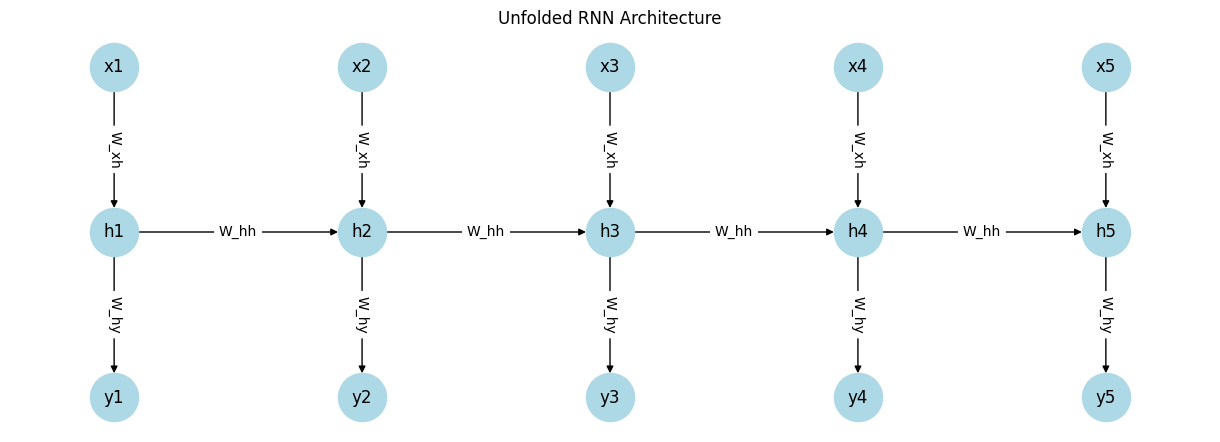

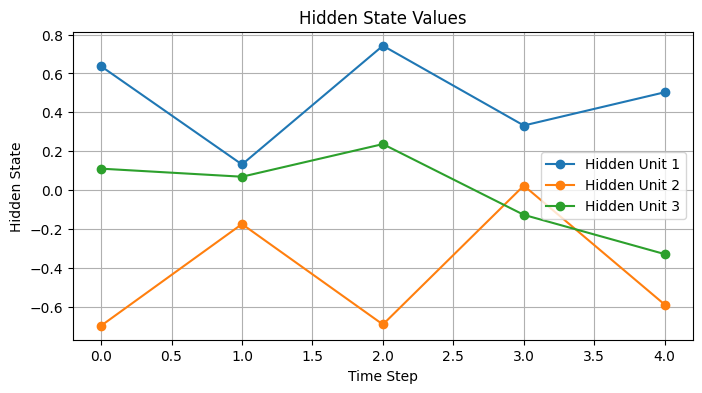

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Five-word input sentence
words = ["I", "love", "deep", "learning", "AI"]
X = np.random.rand(1, 5, 4).astype('float32')

# Build SimpleRNN
inputs = tf.keras.Input(shape=(5, 4))
rnn = tf.keras.layers.SimpleRNN(
    3, return_sequences=True, activation='tanh'
)
states = rnn(inputs)
outputs = tf.keras.layers.TimeDistributed(
    tf.keras.layers.Dense(1)
)(states)

model = tf.keras.Model(inputs, outputs)
model.predict(X, verbose=0)

# Extract weights
Wxh, Whh, bias = rnn.get_weights()
Why, by = model.layers[-1].layer.get_weights()

print("Input weights:", Wxh.shape)
print("Recurrent weights:", Whh.shape)
print("Output weights:", Why.shape)

# Calculate hidden states manually
hidden = np.zeros(3)
hidden_states = []

for t in range(5):
    hidden = np.tanh(X[0, t] @ Wxh + hidden @ Whh + bias)
    hidden_states.append(hidden.copy())

hidden_states = np.array(hidden_states)

# Verify with Keras
keras_states = rnn(X)[0].numpy()
print("Manual and Keras values match:",
      np.allclose(hidden_states, keras_states[0], atol=1e-5))

# Draw unfolded network
G = nx.DiGraph()
pos = {}

for i in range(5):
    G.add_node(f"x{i+1}")
    G.add_node(f"h{i+1}")
    G.add_node(f"y{i+1}")

    pos[f"x{i+1}"] = (i * 2, 2)
    pos[f"h{i+1}"] = (i * 2, 1)
    pos[f"y{i+1}"] = (i * 2, 0)

    G.add_edge(f"x{i+1}", f"h{i+1}", label="W_xh")
    G.add_edge(f"h{i+1}", f"y{i+1}", label="W_hy")

    if i > 0:
        G.add_edge(f"h{i}", f"h{i+1}", label="W_hh")

plt.figure(figsize=(12, 4))
nx.draw(G, pos, with_labels=True, node_color='lightblue',
        node_size=1200, arrows=True)
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=nx.get_edge_attributes(G, 'label')
)
plt.title("Unfolded RNN Architecture")
plt.show()

# Plot hidden states
plt.figure(figsize=(8, 4))
for i in range(3):
    plt.plot(hidden_states[:, i], marker='o',
             label=f"Hidden Unit {i+1}")

plt.xlabel("Time Step")
plt.ylabel("Hidden State")
plt.title("Hidden State Values")
plt.legend()
plt.grid()
plt.show()